# Machine Learning Lab Assignment 3
## Linear Regression to Predict the Selling Price of a House
**Dataset:** `house_price_dataset.csv`

**Objective:**
- Perform linear regression to predict the selling price of a house.
- Evaluate model quality using performance metrics including $R^2$, MAE, and RMSE.
- Generate and display Actual vs. Predicted plots comparing Simple (single-feature) vs. Multiple (all-feature) Linear Regression.


House Price Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


,Model,R² Score,MAE ($),RMSE ($)
0,Simple Linear Regression (Area Only),0.2729,1474748.13,1917103.70
1,Multiple Linear Regression (All Features),0.6529,970043.40,1324506.96


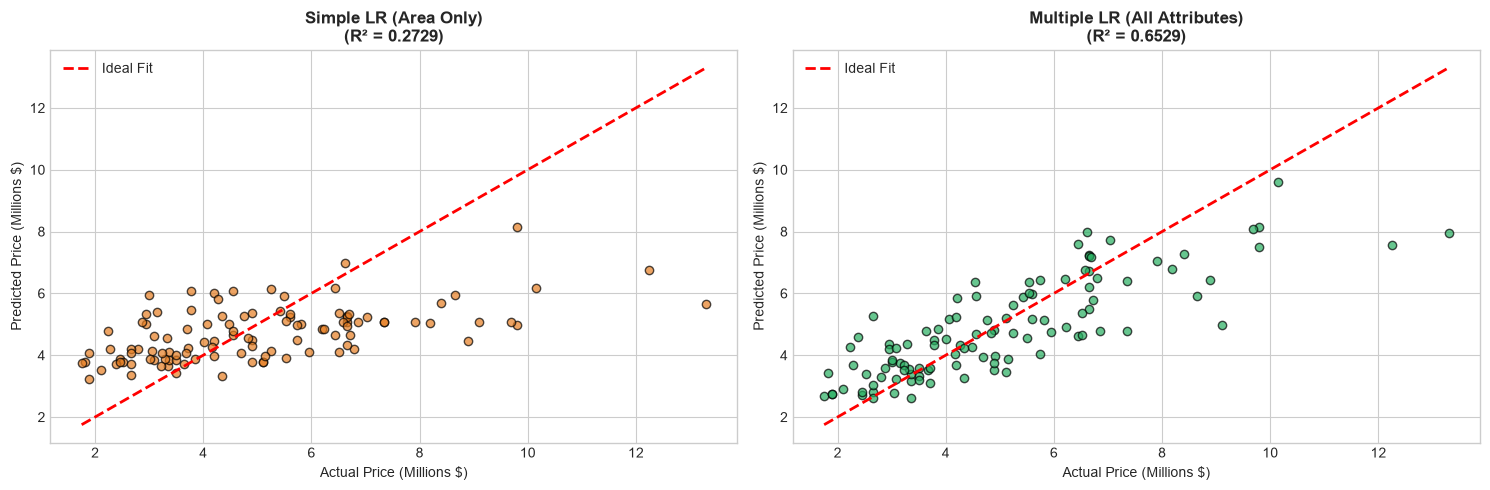

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

df = pd.read_csv('house_price_dataset.csv')
print(f"House Price Dataset Shape: {df.shape}")
display(df.head())

# Preprocessing: One-hot encode categorical attributes
df_enc = pd.get_dummies(df, drop_first=True, dtype=float)

# Task 3A: Simple Linear Regression (Feature = 'area')
X_simple = df_enc[['area']]
y = df_enc['price']

# Task 3B: Multiple Linear Regression (All structural & amenity features)
X_multi = df_enc.drop(columns=['price'])

# Train-Test Split (80/20) with identical random state for fair comparison
X_tr_s, X_te_s, y_tr, y_te = train_test_split(X_simple, y, test_size=0.20, random_state=42)
X_tr_m, X_te_m, _, _ = train_test_split(X_multi, y, test_size=0.20, random_state=42)

# Train Both Models
lr_simple = LinearRegression().fit(X_tr_s, y_tr)
lr_multi = LinearRegression().fit(X_tr_m, y_tr)

# Predictions
y_pred_s = lr_simple.predict(X_te_s)
y_pred_m = lr_multi.predict(X_te_m)

# Evaluation Metrics Table
results_3 = pd.DataFrame([
    {
        'Model': 'Simple Linear Regression (Area Only)',
        'R² Score': round(r2_score(y_te, y_pred_s), 4),
        'MAE ($)': round(mean_absolute_error(y_te, y_pred_s), 2),
        'RMSE ($)': round(np.sqrt(mean_squared_error(y_te, y_pred_s)), 2)
    },
    {
        'Model': 'Multiple Linear Regression (All Features)',
        'R² Score': round(r2_score(y_te, y_pred_m), 4),
        'MAE ($)': round(mean_absolute_error(y_te, y_pred_m), 2),
        'RMSE ($)': round(np.sqrt(mean_squared_error(y_te, y_pred_m)), 2)
    }
])
display(results_3)

# Actual vs Predicted Plots for Both Tasks
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Simple LR Plot
axes[0].scatter(y_te / 1e6, y_pred_s / 1e6, color='#e67e22', alpha=0.7, edgecolors='k')
axes[0].plot([y_te.min() / 1e6, y_te.max() / 1e6], [y_te.min() / 1e6, y_te.max() / 1e6], 'r--', lw=2, label='Ideal Fit')
axes[0].set_title(f"Simple LR (Area Only)\n(R² = {results_3.loc[0, 'R² Score']:.4f})", fontweight='bold')
axes[0].set_xlabel('Actual Price (Millions $)')
axes[0].set_ylabel('Predicted Price (Millions $)')
axes[0].legend()

# Multiple LR Plot
axes[1].scatter(y_te / 1e6, y_pred_m / 1e6, color='#27ae60', alpha=0.7, edgecolors='k')
axes[1].plot([y_te.min() / 1e6, y_te.max() / 1e6], [y_te.min() / 1e6, y_te.max() / 1e6], 'r--', lw=2, label='Ideal Fit')
axes[1].set_title(f"Multiple LR (All Attributes)\n(R² = {results_3.loc[1, 'R² Score']:.4f})", fontweight='bold')
axes[1].set_xlabel('Actual Price (Millions $)')
axes[1].set_ylabel('Predicted Price (Millions $)')
axes[1].legend()

plt.tight_layout()
plt.show()


### Conclusion for Assignment 3:
- Simple Linear Regression on `area` alone explains only $27.3\%$ of price variance, indicating that square footage by itself is inadequate for pricing.
- Multiple Linear Regression incorporating bathrooms, stories, air conditioning, and location preferences substantially boosts predictive accuracy to $R^2 = 0.653$, reducing RMSE significantly.
